# Historical binary experiment
Preserved for reference. Active 10-class experiments and run commands are in `README.md` and `docs/TECHNIQUES_AND_RUNS.md`. These notebook outputs use binary `label` and must not be compared directly with multiclass results.

# 02. BASELINE CENTRALIZED CHUẨN (UNSW-NB15), CÓ VALIDATION VÀ TINH CHỈNH

Baseline **tập trung** làm mốc tham chiếu cho kiến trúc federated.

### Quy trình
1. **Nạp dữ liệu đã tiền xử lý** từ `01_preprocessing.ipynb` (`output_preprocess/data.npz`), cùng cách xử lý với nhóm federated. Cần chạy notebook 01 trước.
2. **Kiểm tra trùng lặp** và **tách validation theo nhóm trùng lặp** (khoảng 80/20, phân tầng theo `attack_cat`, seed cố định). Các dòng có đặc trưng giống hệt nhau luôn nằm cùng một phía, nên validation không chứa bản sao của dữ liệu train.
3. **Tinh chỉnh hyperparameter** bằng random search trên validation, cho 4 mô hình.
4. **Chọn ngưỡng quyết định** trên validation (3 điểm hoạt động, xem bên dưới).
5. Huấn luyện lại trên phần train (80%) với cấu hình tốt nhất, **5 seed**, rồi chấm **một lần** trên tập test chính thức. Tập test không dùng để chọn bất cứ thứ gì.
6. So sánh cấu hình **mặc định** (cấu hình ban đầu, chưa tinh chỉnh) với cấu hình **đã tinh chỉnh**.
7. Báo cáo trên **toàn bộ test** (để so được với các nghiên cứu khác) và trên **phần test chưa thấy** (các dòng không có bản sao y hệt trong train).

### Ba điểm hoạt động (ngưỡng)
| Điểm | Cách chọn (trên validation) |
|---|---|
| `τ=0,5` | Ngưỡng mặc định |
| `Youden` | Ngưỡng cực đại hóa (TPR − FPR). Không phụ thuộc tỷ lệ lớp |
| `FPR≤10%` | Ngưỡng cho recall cao nhất khi FPR trên validation không vượt 10% |

Train có 68% tấn công còn test chỉ 55%. Vì ngưỡng chọn trên validation phản ánh tỷ lệ 68%, nên `Youden` (không phụ thuộc tỷ lệ lớp) và `FPR≤10%` (chỉ phụ thuộc phần Normal) được chọn thay cho ngưỡng cực đại hóa F1.

### Ràng buộc để tương thích federated
LR và MLP chỉ tìm trong không gian **SGD, không momentum** (phù hợp với FedAvg).

In [1]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import loguniform
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import ParameterSampler, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')

SEEDS = [0, 1, 2, 3, 4]
SPLIT_SEED = 42
N_FOLDS = 5            # validation = 1 fold trong 5 (khoảng 20%)
SEARCH_SEED = 0
N_BOOT = 1000          # số lần bootstrap
BOOT_SEED = 123
N_TRIALS = {'Logistic Regression': 15, 'MLP': 12, 'XGBoost': 20, 'Random Forest': 12}
TARGET_FPR = 0.10
PRE_DIR = 'output_preprocess'   # đầu ra của 01_preprocessing.ipynb
OUT_DIR = 'output_baseline'
MODEL_DIR = os.path.join(OUT_DIR, 'models')
os.makedirs(MODEL_DIR, exist_ok=True)

DATA_DIR = os.path.join('CSV Files', 'Training and Testing Sets')
train_path = os.path.join(DATA_DIR, 'UNSW_NB15_training-set.csv') if os.path.exists(os.path.join(DATA_DIR, 'UNSW_NB15_training-set.csv')) else 'UNSW_NB15_training-set.csv'
test_path  = os.path.join(DATA_DIR, 'UNSW_NB15_testing-set.csv') if os.path.exists(os.path.join(DATA_DIR, 'UNSW_NB15_testing-set.csv')) else 'UNSW_NB15_testing-set.csv' 
MODELS = ['Logistic Regression', 'MLP', 'XGBoost', 'Random Forest']
print('Seeds:', SEEDS, '| số lần thử:', N_TRIALS)

Seeds: [0, 1, 2, 3, 4] | số lần thử: {'Logistic Regression': 15, 'MLP': 12, 'XGBoost': 20, 'Random Forest': 12}


## Phần 1: Nạp dữ liệu đã tiền xử lý

In [9]:
d = np.load(os.path.join(PRE_DIR, 'data.npz'), allow_pickle=False)
X_full, y_all, attack_cat = d['X_train'], d['y_train'], d['attack_cat_train']
X_test, y_test, test_cat = d['X_test'], d['y_test'], d['attack_cat_test']   # test_cat chỉ dùng để báo cáo
FEATS = list(d['features'])
CATS = [c for c in pd.Series(test_cat).value_counts().index if c != 'Normal']

# dữ liệu thô chỉ dùng để tìm các dòng trùng lặp ở Phần 2
raw = pd.read_csv(train_path, encoding='utf-8-sig')
test_raw = pd.read_csv(test_path, encoding='utf-8-sig')
assert len(raw) == len(X_full) and len(test_raw) == len(X_test)
assert (raw['label'].values == y_all).all() and (test_raw['label'].values == y_test).all()
print('Train đầy đủ:', X_full.shape, '| Test:', X_test.shape)

Train đầy đủ: (175341, 191) | Test: (82332, 191)


## Phần 2: Kiểm tra trùng lặp

Hai dòng được coi là trùng khi **toàn bộ 42 đặc trưng** giống hệt nhau (không tính `id`, `attack_cat`, `label`). Nếu tách validation ngẫu nhiên, các bản sao sẽ rơi vào cả train lẫn validation, khiến điểm validation bị thổi phồng và việc tinh chỉnh ưu tiên mô hình học thuộc.

In [12]:
FEAT_RAW = [c for c in raw.columns if c not in ('id', 'attack_cat', 'label')]
h_train = pd.util.hash_pandas_object(raw[FEAT_RAW], index=False).values
h_test = pd.util.hash_pandas_object(test_raw[FEAT_RAW], index=False).values

def dup_report(name, h, y, cat):
    s = pd.Series(h)
    g = pd.DataFrame({'h': h, 'y': y})
    conflict = g.groupby('h')['y'].nunique()
    return {'Tập': name, 'Số dòng': len(h), 'Nhóm duy nhất': s.nunique(),
            'Dòng thừa': int(s.duplicated().sum()), '% dòng thừa': round(s.duplicated().mean() * 100, 1),
            'Nhóm nhãn mâu thuẫn': int((conflict > 1).sum())}

display(pd.DataFrame([dup_report('train', h_train, y_all, attack_cat),
                      dup_report('test', h_test, y_test, test_cat)]).set_index('Tập'))

red = pd.DataFrame({'train': pd.Series(pd.Series(h_train).duplicated().values, index=attack_cat).groupby(level=0).mean(),
                    'test': pd.Series(pd.Series(h_test).duplicated().values, index=test_cat).groupby(level=0).mean()})
print('% dòng thừa theo loại:')
display((red * 100).round(1).sort_values('train', ascending=False))

seen = np.isin(h_test, np.unique(h_train))   
print(f'Dòng test có bản sao y hệt trong train: {seen.sum():,} ({seen.mean():.1%})')
print('  theo loại:', pd.Series(test_cat[seen]).value_counts().to_dict())
print(f'Phần test chưa thấy: {(~seen).sum():,} dòng, tỷ lệ tấn công {y_test[~seen].mean():.2%}')

,Số dòng,Nhóm duy nhất,Dòng thừa,% dòng thừa,Nhóm nhãn mâu thuẫn
Tập,,,,,
train,175341,101040,74301,42.4,229
test,82332,53946,28386,34.5,6


% dòng thừa theo loại:


,train,test
Generic,90.2,80.7
DoS,75.5,67.8
Analysis,72.9,53.9
Backdoor,70.6,88.0
Exploits,43.9,36.0
Reconnaissance,38.8,29.4
Fuzzers,18.1,27.5
Normal,7.5,7.6
Worms,6.9,2.3
Shellcode,3.9,0.3


Dòng test có bản sao y hệt trong train: 8,541 (10.4%)
  theo loại: {'DoS': 2004, 'Exploits': 1802, 'Generic': 1722, 'Normal': 1472, 'Reconnaissance': 1138, 'Fuzzers': 261, 'Analysis': 125, 'Shellcode': 13, 'Backdoor': 4}
Phần test chưa thấy: 73,791 dòng, tỷ lệ tấn công 51.85%


## Phần 3: Tách validation theo nhóm trùng lặp

Dùng `StratifiedGroupKFold`: **nhóm** là các dòng giống hệt nhau, **phân tầng** theo `attack_cat`. Lấy 1 fold trong 5 làm validation. Tách một lần với seed cố định, dùng chung cho mọi mô hình.

Dữ liệu train **không loại trùng**: các luồng lặp lại vẫn được giữ, để kết quả so được với các nghiên cứu dùng bộ dữ liệu chuẩn.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SPLIT_SEED)
idx_tr, idx_val = next(sgkf.split(np.zeros(len(raw)), attack_cat, groups=h_train))
X_tr, y_tr = X_full[idx_tr], y_all[idx_tr]
X_val, y_val = X_full[idx_val], y_all[idx_val]

leak = np.isin(h_train[idx_val], np.unique(h_train[idx_tr])).sum()
print(f'Train: {len(idx_tr):,} | Validation: {len(idx_val):,} ({len(idx_val)/len(raw):.1%}) | Test: {len(y_test):,}')
print(f'Dòng validation có bản sao trong train: {leak} (phải bằng 0)')
assert leak == 0
print('Tỷ lệ tấn công: train {:.2%} | val {:.2%} | test {:.2%}'.format(y_tr.mean(), y_val.mean(), y_test.mean()))
cmp = pd.DataFrame({'train': pd.Series(attack_cat[idx_tr]).value_counts(),
                    'val': pd.Series(attack_cat[idx_val]).value_counts()}).fillna(0).astype(int)
cmp['val %'] = (cmp['val'] / cmp.sum(axis=1) * 100).round(1)
display(cmp)

Train: 140,273 | Validation: 35,068 (20.0%) | Test: 82,332
Dòng validation có bản sao trong train: 0 (phải bằng 0)
Tỷ lệ tấn công: train 68.06% | val 68.06% | test 55.06%


,train,val,val %
Normal,44800,11200,20.0
Generic,32000,8000,20.0
Exploits,26714,6679,20.0
Fuzzers,14548,3636,20.0
DoS,9811,2453,20.0
Reconnaissance,8393,2098,20.0
Analysis,1600,400,20.0
Backdoor,1397,349,20.0
Shellcode,906,227,20.0
Worms,104,26,20.0


## Phần 4: Không gian tìm kiếm và mô hình

In [13]:
SPACES = {
    'Logistic Regression': {
        'alpha': loguniform(1e-6, 1e-2), 'eta0': loguniform(1e-3, 0.3), 'epochs': [10, 20, 30, 60]},
    'MLP': {
        'hidden': [(64,), (128,), (128, 64), (256, 128), (128, 64, 32)],
        'lr': loguniform(5e-3, 0.2), 'alpha': loguniform(1e-6, 1e-2),
        'batch_size': [128, 256, 512], 'epochs': [20, 30, 60]},
    'XGBoost': {
        'n_estimators': [100, 200, 300, 500], 'max_depth': [4, 6, 8, 10],
        'learning_rate': loguniform(0.03, 0.3), 'subsample': [0.7, 0.85, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 3, 5],
        'reg_lambda': loguniform(0.1, 10)},
    'Random Forest': {
        'n_estimators': [100, 200, 300], 'max_depth': [10, 15, 20, None],
        'min_samples_leaf': [1, 2, 5], 'max_features': ['sqrt', 0.3, 0.5]},
}
DEFAULTS = {
    'Logistic Regression': {'alpha': 1e-4, 'eta0': 0.05, 'epochs': 30},
    'MLP': {'hidden': (128, 64), 'lr': 0.05, 'alpha': 1e-4, 'batch_size': 256, 'epochs': 30},
    'XGBoost': {'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.1},
    'Random Forest': {'n_estimators': 100, 'max_depth': 15},
}

def make_model(name, p, seed):
    if name == 'Logistic Regression':
        return SGDClassifier(loss='log_loss', alpha=p['alpha'], learning_rate='constant', eta0=p['eta0'],
                             max_iter=p['epochs'], tol=None, shuffle=True, random_state=seed)
    if name == 'MLP':
        return MLPClassifier(hidden_layer_sizes=p['hidden'], solver='sgd', momentum=0.0,
                             nesterovs_momentum=False, learning_rate_init=p['lr'], batch_size=p['batch_size'],
                             alpha=p['alpha'], max_iter=p['epochs'], random_state=seed)
    if name == 'XGBoost':
        return XGBClassifier(**p, eval_metric='logloss', random_state=seed, n_jobs=-1)
    return RandomForestClassifier(**p, random_state=seed, n_jobs=-1)

def model_size(name, m):
    if name == 'Logistic Regression': return m.coef_.size + m.intercept_.size
    if name == 'MLP': return sum(c.size for c in m.coefs_) + sum(b.size for b in m.intercepts_)
    if name == 'XGBoost': return m.get_booster().num_boosted_rounds()
    return len(m.estimators_)

def clean_params(p):
    out = {}
    for k, v in p.items():
        out[k] = float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, (np.integer,)) else v)
    return out
print('Đã định nghĩa không gian tìm kiếm.')

Đã định nghĩa không gian tìm kiếm.


## Phần 5: Random search trên validation

Với mỗi mô hình, thử `N_TRIALS` tổ hợp ngẫu nhiên, huấn luyện trên **train** và chấm **ROC-AUC trên validation**. Tổ hợp lỗi hoặc phân kỳ (xác suất NaN) bị loại. Cấu hình mặc định cũng được chấm để so sánh.

In [14]:
def val_auc(name, p, seed=SEARCH_SEED):
    t0 = time.time()
    try:
        m = make_model(name, p, seed).fit(X_tr, y_tr)
        pv = m.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, pv) if np.isfinite(pv).all() else np.nan
    except Exception as e:
        auc = np.nan
    return auc, time.time() - t0

trials, best = [], {}
t_all = time.time()
for name in MODELS:
    auc0, t0_ = val_auc(name, DEFAULTS[name])
    trials.append({'Mô hình': name, 'Loại': 'Mặc định', 'Val ROC-AUC': auc0, 'Thời gian (s)': t0_,
                   'Tham số': str(DEFAULTS[name])})
    cands = list(ParameterSampler(SPACES[name], n_iter=N_TRIALS[name], random_state=SEARCH_SEED))
    scored = []
    for p in cands:
        p = clean_params(p)
        auc, t = val_auc(name, p)
        scored.append((auc, p))
        trials.append({'Mô hình': name, 'Loại': 'Thử', 'Val ROC-AUC': auc, 'Thời gian (s)': t, 'Tham số': str(p)})
    scored = [(a, p) for a, p in scored if np.isfinite(a)]
    a_best, p_best = max(scored, key=lambda x: x[0])
    best[name] = p_best
    print(f'{name:20s} | mặc định val AUC={auc0:.4f} | tốt nhất={a_best:.4f} | {time.time()-t_all:.0f}s tích lũy')

trials = pd.DataFrame(trials)
json.dump({k: {a: (list(b) if isinstance(b, tuple) else b) for a, b in v.items()} for k, v in best.items()},
          open(os.path.join(OUT_DIR, 'best_params.json'), 'w'), indent=2, ensure_ascii=False)
print(f'Tổng thời gian tìm kiếm: {time.time()-t_all:.0f}s')

Logistic Regression  | mặc định val AUC=0.9723 | tốt nhất=0.9856 | 40s tích lũy
MLP                  | mặc định val AUC=0.9903 | tốt nhất=0.9912 | 173s tích lũy
XGBoost              | mặc định val AUC=0.9933 | tốt nhất=0.9934 | 245s tích lũy
Random Forest        | mặc định val AUC=0.9917 | tốt nhất=0.9930 | 501s tích lũy
Tổng thời gian tìm kiếm: 501s


In [7]:
rows = []
for name in MODELS:
    d = trials[(trials['Mô hình'] == name) & (trials['Loại'] == 'Mặc định')]['Val ROC-AUC'].iloc[0]
    t = trials[(trials['Mô hình'] == name) & (trials['Loại'] == 'Thử')]['Val ROC-AUC']
    rows.append({'Mô hình': name, 'Val AUC mặc định': d, 'Val AUC tốt nhất': t.max(),
                 'Cải thiện': t.max() - d, 'Trung vị các lần thử': t.median(),
                 'Số lần lỗi/phân kỳ': int(t.isna().sum())})
display(pd.DataFrame(rows).set_index('Mô hình').round(4))
print('Cấu hình tốt nhất:')
for k, v in best.items():
    print(f'  {k:20s}: {v}')

,Val AUC mặc định,Val AUC tốt nhất,Cải thiện,Trung vị các lần thử,Số lần lỗi/phân kỳ
Mô hình,,,,,
Logistic Regression,0.9723,0.9856,0.0133,0.9823,0
MLP,0.9903,0.9912,0.0009,0.9900,0
XGBoost,0.9933,0.9934,0.0002,0.9929,0
Random Forest,0.9917,0.9930,0.0013,0.9918,0


Cấu hình tốt nhất:
  Logistic Regression : {'alpha': 2.231090560744303e-06, 'epochs': 60, 'eta0': 0.008169189024867433}
  MLP                 : {'alpha': 0.0001410889228367583, 'batch_size': 128, 'epochs': 60, 'hidden': (128, 64, 32), 'lr': 0.028688397387750718}
  XGBoost             : {'colsample_bytree': 1.0, 'learning_rate': 0.11299721774595123, 'max_depth': 8, 'min_child_weight': 5, 'n_estimators': 500, 'reg_lambda': 0.10440310373117892, 'subsample': 1.0}
  Random Forest       : {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 20}


## Phần 6: Huấn luyện cuối, chọn ngưỡng trên validation, chấm trên test

Với mỗi seed và mỗi mô hình, hai cấu hình (mặc định và tinh chỉnh) được huấn luyện trên phần **train** (80%). Ba điểm hoạt động được chọn bằng **xác suất trên validation**, rồi áp dụng nguyên cho test.

In [8]:
def fpr_of(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return fp / (fp + tn)

def thresholds_from_val(pv):
    fpr, tpr, thr = roc_curve(y_val, pv)
    thr = np.where(np.isinf(thr), 1.0, thr)
    j = np.argmax(tpr - fpr)
    ok = fpr <= TARGET_FPR
    k = np.where(ok)[0][np.argmax(tpr[ok])]
    return {'τ=0,5': 0.5, 'Youden': float(thr[j]), 'FPR≤10%': float(thr[k])}

OPS = ['τ=0,5', 'Youden', 'FPR≤10%']
TEST_SUBSETS = {'Toàn bộ': np.ones(len(y_test), dtype=bool), 'Chưa thấy': ~seen}
rows, cat_rows, probs0 = [], [], {}
t_all = time.time()
for seed in SEEDS:
    for name in MODELS:
        for cfg, params in [('Mặc định', DEFAULTS[name]), ('Tinh chỉnh', best[name])]:
            m = make_model(name, params, seed)
            t0 = time.time()
            m.fit(X_tr, y_tr)
            train_s = time.time() - t0
            pv = m.predict_proba(X_val)[:, 1]
            t0 = time.time()
            pt = m.predict_proba(X_test)[:, 1]
            infer_ms = (time.time() - t0) / len(X_test) * 1e6
            thr = thresholds_from_val(pv)
            auc_v = roc_auc_score(y_val, pv)
            for op in OPS:
                pred = (pt >= thr[op]).astype(int)
                for subset, mask in TEST_SUBSETS.items():
                    ys, ps, prs = y_test[mask], pred[mask], pt[mask]
                    rows.append({'Mô hình': name, 'Cấu hình': cfg, 'Seed': seed, 'Điểm hoạt động': op, 'Tập test': subset,
                                 'τ': thr[op], 'Accuracy': accuracy_score(ys, ps),
                                 'Precision': precision_score(ys, ps, zero_division=0), 'Recall': recall_score(ys, ps),
                                 'FPR': fpr_of(ys, ps), 'F1': f1_score(ys, ps),
                                 'ROC-AUC (test)': roc_auc_score(ys, prs), 'AP (test)': average_precision_score(ys, prs),
                                 'ROC-AUC (val)': auc_v,
                                 'Train s': train_s, 'Infer ms/1k': infer_ms, 'Kích thước': model_size(name, m)})
                for c in CATS:
                    cat_rows.append({'Mô hình': name, 'Cấu hình': cfg, 'Seed': seed, 'Điểm hoạt động': op,
                                     'Loại': c, 'Recall': pred[test_cat == c].mean()})
            if seed == SEEDS[0] and cfg == 'Tinh chỉnh':
                probs0[name] = (pt, thr)
                joblib.dump(m, os.path.join(MODEL_DIR, f"{name.replace(' ', '_').lower()}.joblib"))
    print(f'seed {seed} xong ({time.time()-t_all:.0f}s tích lũy)')

res_all = pd.DataFrame(rows)
cats = pd.DataFrame(cat_rows)
res_all.to_csv(os.path.join(OUT_DIR, 'runs.csv'), index=False)
cats.to_csv(os.path.join(OUT_DIR, 'per_category.csv'), index=False)
res = res_all[res_all['Tập test'] == 'Toàn bộ']          # các bảng chính dùng toàn bộ test
print(f'Tổng thời gian: {time.time()-t_all:.0f}s | số dòng kết quả: {len(res_all)}')

seed 0 xong (54s tích lũy)


seed 1 xong (108s tích lũy)


seed 2 xong (162s tích lũy)


seed 3 xong (217s tích lũy)


seed 4 xong (270s tích lũy)
Tổng thời gian: 270s | số dòng kết quả: 240


## Phần 7: Kết quả cấu hình đã tinh chỉnh (trung bình ± std qua 5 seed)

Trên tập test chính thức. Precision, Recall, F1 là của lớp Tấn công. **FPR** là tỷ lệ luồng bình thường bị báo nhầm. Ngưỡng ở `Youden` và `FPR≤10%` chọn trên validation.

In [9]:
metric_cols = ['Recall', 'Precision', 'FPR', 'F1', 'Accuracy']
tuned = res[res['Cấu hình'] == 'Tinh chỉnh']

def ms(df, col):
    g = df.groupby('Mô hình')[col].agg(['mean', 'std']).loc[MODELS]
    return g.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)

for op in OPS:
    sub = tuned[tuned['Điểm hoạt động'] == op]
    t = pd.DataFrame({c: ms(sub, c) for c in metric_cols})
    t.insert(0, 'τ (TB)', sub.groupby('Mô hình')['τ'].mean().loc[MODELS].round(3))
    print(f'\n=== Điểm hoạt động: {op} ===')
    display(t)

print('\n=== Chỉ số không phụ thuộc ngưỡng, và chi phí ===')
base = tuned[tuned['Điểm hoạt động'] == 'τ=0,5']
free = pd.DataFrame({'ROC-AUC (test)': ms(base, 'ROC-AUC (test)'), 'AP (test)': ms(base, 'AP (test)'),
                     'ROC-AUC (val)': ms(base, 'ROC-AUC (val)')})
free['Train s'] = base.groupby('Mô hình')['Train s'].mean().loc[MODELS].round(2)
free['Infer ms/1k'] = base.groupby('Mô hình')['Infer ms/1k'].mean().loc[MODELS].round(3)
free['Kích thước (tham số/cây)'] = base.groupby('Mô hình')['Kích thước'].mean().loc[MODELS].astype(int)
display(free)

summary = (tuned.groupby(['Mô hình', 'Điểm hoạt động'])
           [['Recall', 'Precision', 'FPR', 'F1', 'Accuracy', 'ROC-AUC (test)', 'AP (test)']].agg(['mean', 'std']))
summary.columns = [f'{m} {s}' for m, s in summary.columns]
summary.round(4).to_csv(os.path.join(OUT_DIR, 'summary.csv'))


=== Điểm hoạt động: τ=0,5 ===


,τ (TB),Recall,Precision,FPR,F1,Accuracy
Mô hình,,,,,,
Logistic Regression,0.5,0.9805 ± 0.0131,0.7751 ± 0.0192,0.3497 ± 0.0413,0.8656 ± 0.0066,0.8321 ± 0.0114
MLP,0.5,0.9775 ± 0.0043,0.8253 ± 0.0151,0.2539 ± 0.0264,0.8949 ± 0.0079,0.8735 ± 0.0107
XGBoost,0.5,0.9784 ± 0.0000,0.8185 ± 0.0000,0.2658 ± 0.0000,0.8914 ± 0.0000,0.8687 ± 0.0000
Random Forest,0.5,0.9882 ± 0.0003,0.8151 ± 0.0004,0.2747 ± 0.0007,0.8933 ± 0.0003,0.8700 ± 0.0004



=== Điểm hoạt động: Youden ===


,τ (TB),Recall,Precision,FPR,F1,Accuracy
Mô hình,,,,,,
Logistic Regression,0.761,0.9274 ± 0.0084,0.8504 ± 0.0104,0.2001 ± 0.0179,0.8872 ± 0.0021,0.8701 ± 0.0037
MLP,0.684,0.9557 ± 0.0034,0.8826 ± 0.0088,0.1559 ± 0.0135,0.9177 ± 0.0046,0.9055 ± 0.0057
XGBoost,0.729,0.9541 ± 0.0000,0.8792 ± 0.0000,0.1605 ± 0.0000,0.9152 ± 0.0000,0.9026 ± 0.0000
Random Forest,0.662,0.9623 ± 0.0038,0.8781 ± 0.0077,0.1639 ± 0.0124,0.9182 ± 0.0025,0.9056 ± 0.0035



=== Điểm hoạt động: FPR≤10% ===


,τ (TB),Recall,Precision,FPR,F1,Accuracy
Mô hình,,,,,,
Logistic Regression,0.671,0.9527 ± 0.0009,0.8147 ± 0.0031,0.2655 ± 0.0054,0.8783 ± 0.0019,0.8547 ± 0.0025
MLP,0.480,0.9794 ± 0.0041,0.8181 ± 0.0020,0.2667 ± 0.0041,0.8915 ± 0.0017,0.8688 ± 0.0020
XGBoost,0.434,0.9831 ± 0.0000,0.8043 ± 0.0000,0.2931 ± 0.0000,0.8847 ± 0.0000,0.8589 ± 0.0000
Random Forest,0.487,0.9895 ± 0.0002,0.8107 ± 0.0006,0.2830 ± 0.0011,0.8913 ± 0.0004,0.8670 ± 0.0006



=== Chỉ số không phụ thuộc ngưỡng, và chi phí ===


,ROC-AUC (test),AP (test),ROC-AUC (val),Train s,Infer ms/1k,Kích thước (tham số/cây)
Mô hình,,,,,,
Logistic Regression,0.9630 ± 0.0008,0.9719 ± 0.0011,0.9853 ± 0.0006,3.22,0.038,192
MLP,0.9801 ± 0.0014,0.9852 ± 0.0009,0.9911 ± 0.0001,15.58,0.273,34945
XGBoost,0.9812 ± 0.0000,0.9863 ± 0.0000,0.9934 ± 0.0000,3.42,0.818,500
Random Forest,0.9821 ± 0.0002,0.9864 ± 0.0001,0.9930 ± 0.0000,18.94,1.800,300


## Phần 8: Mặc định so với tinh chỉnh

Tinh chỉnh có thực sự cải thiện kết quả trên test không? (Cả hai cấu hình đều chấm trên test chỉ để báo cáo; việc chọn cấu hình tinh chỉnh chỉ dựa trên validation.)

In [10]:
def comp(col, op='τ=0,5'):
    sub = res[res['Điểm hoạt động'] == op]
    g = sub.groupby(['Mô hình', 'Cấu hình'])[col].agg(['mean', 'std'])
    t = g.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1).unstack('Cấu hình')[['Mặc định', 'Tinh chỉnh']]
    d = (sub[sub['Cấu hình'] == 'Tinh chỉnh'].groupby('Mô hình')[col].mean()
         - sub[sub['Cấu hình'] == 'Mặc định'].groupby('Mô hình')[col].mean())
    t['Δ'] = d.map('{:+.4f}'.format)
    return t.loc[MODELS]

for col in ['ROC-AUC (val)', 'ROC-AUC (test)', 'AP (test)']:
    print(f'\n=== {col} ===')
    display(comp(col))
for col in ['F1', 'FPR', 'Recall']:
    print(f'\n=== {col} tại τ=0,5 ===')
    display(comp(col))
print('\n=== Recall tại điểm hoạt động FPR≤10% (chọn trên validation) ===')
display(comp('Recall', 'FPR≤10%'))
print('\n=== FPR thực tế trên test tại điểm hoạt động FPR≤10% (mục tiêu 10% trên validation) ===')
display(comp('FPR', 'FPR≤10%'))


=== ROC-AUC (val) ===


Cấu hình,Mặc định,Tinh chỉnh,Δ
Mô hình,,,
Logistic Regression,0.9802 ± 0.0045,0.9853 ± 0.0006,+0.0051
MLP,0.9900 ± 0.0003,0.9911 ± 0.0001,+0.0011
XGBoost,0.9933 ± 0.0000,0.9934 ± 0.0000,+0.0002
Random Forest,0.9917 ± 0.0000,0.9930 ± 0.0000,+0.0013



=== ROC-AUC (test) ===


Cấu hình,Mặc định,Tinh chỉnh,Δ
Mô hình,,,
Logistic Regression,0.9526 ± 0.0066,0.9630 ± 0.0008,+0.0105
MLP,0.9778 ± 0.0006,0.9801 ± 0.0014,+0.0022
XGBoost,0.9832 ± 0.0000,0.9812 ± 0.0000,-0.0020
Random Forest,0.9819 ± 0.0001,0.9821 ± 0.0002,+0.0001



=== AP (test) ===


Cấu hình,Mặc định,Tinh chỉnh,Δ
Mô hình,,,
Logistic Regression,0.9625 ± 0.0054,0.9719 ± 0.0011,+0.0094
MLP,0.9834 ± 0.0004,0.9852 ± 0.0009,+0.0018
XGBoost,0.9877 ± 0.0000,0.9863 ± 0.0000,-0.0014
Random Forest,0.9865 ± 0.0000,0.9864 ± 0.0001,-0.0001


... (6 outputs left out)


=== Recall tại điểm hoạt động FPR≤10% (chọn trên validation) ===


Cấu hình,Mặc định,Tinh chỉnh,Δ
Mô hình,,,
Logistic Regression,0.9377 ± 0.0089,0.9527 ± 0.0009,+0.0150
MLP,0.9800 ± 0.0034,0.9794 ± 0.0041,-0.0006
XGBoost,0.9867 ± 0.0000,0.9831 ± 0.0000,-0.0036
Random Forest,0.9853 ± 0.0009,0.9895 ± 0.0002,+0.0042



=== FPR thực tế trên test tại điểm hoạt động FPR≤10% (mục tiêu 10% trên validation) ===


Cấu hình,Mặc định,Tinh chỉnh,Δ
Mô hình,,,
Logistic Regression,0.2574 ± 0.0160,0.2655 ± 0.0054,+0.0081
MLP,0.2622 ± 0.0103,0.2667 ± 0.0041,+0.0045
XGBoost,0.2890 ± 0.0000,0.2931 ± 0.0000,+0.0042
Random Forest,0.2622 ± 0.0019,0.2830 ± 0.0011,+0.0208


## Phần 9: Recall theo từng loại tấn công (cấu hình tinh chỉnh)

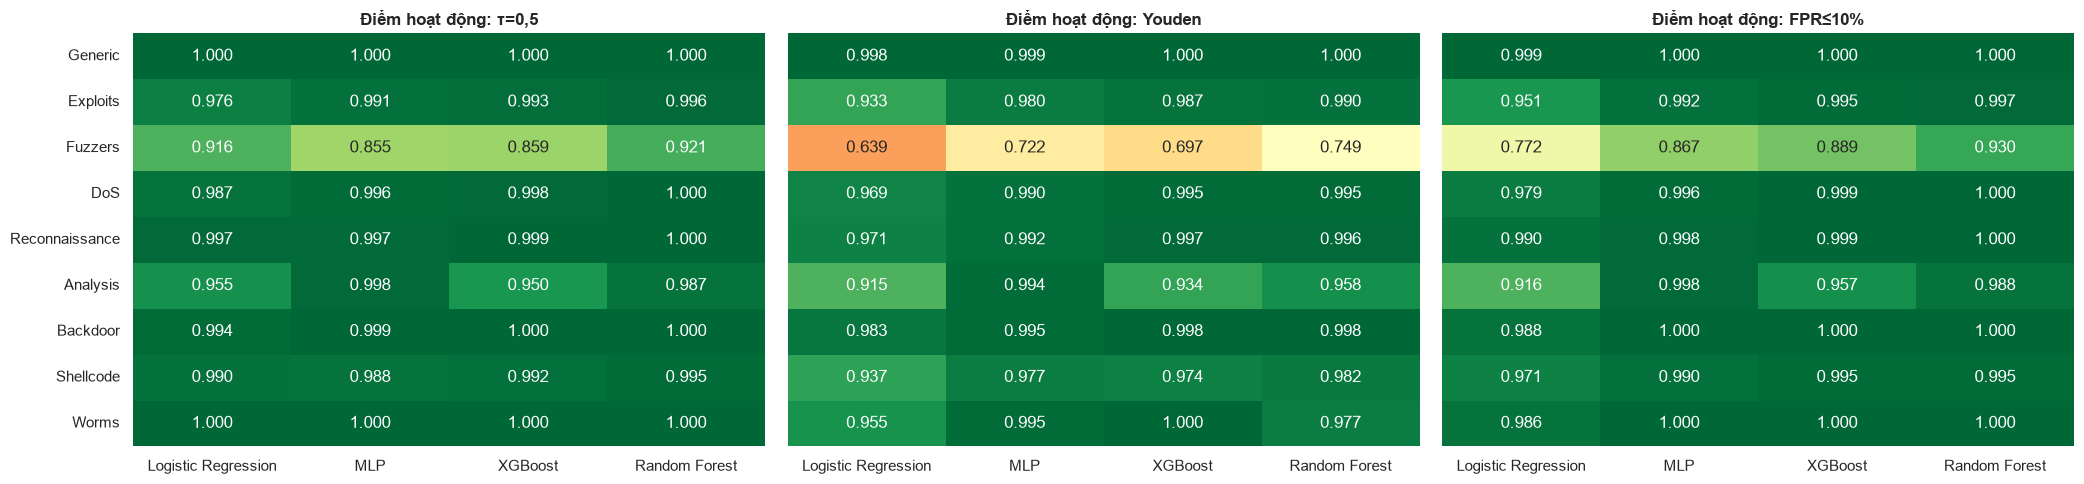

Số mẫu test mỗi loại: {'Generic': 18871, 'Exploits': 11132, 'Fuzzers': 6062, 'DoS': 4089, 'Reconnaissance': 3496, 'Analysis': 677, 'Backdoor': 583, 'Shellcode': 378, 'Worms': 44}

Recall theo loại tại τ=0,5 (trung bình ± std qua seed):


,Số mẫu test,Logistic Regression,MLP,XGBoost,Random Forest
Loại,,,,,
Generic,18871,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
Exploits,11132,0.976 ± 0.016,0.991 ± 0.002,0.993 ± 0.0,0.996 ± 0.0
Fuzzers,6062,0.916 ± 0.062,0.855 ± 0.027,0.859 ± 0.0,0.921 ± 0.003
DoS,4089,0.987 ± 0.004,0.996 ± 0.001,0.998 ± 0.0,1.0 ± 0.0
Reconnaissance,3496,0.997 ± 0.002,0.997 ± 0.001,0.999 ± 0.0,1.0 ± 0.0
Analysis,677,0.955 ± 0.027,0.998 ± 0.002,0.95 ± 0.0,0.987 ± 0.004
Backdoor,583,0.994 ± 0.003,0.999 ± 0.001,1.0 ± 0.0,1.0 ± 0.001
Shellcode,378,0.99 ± 0.008,0.988 ± 0.004,0.992 ± 0.0,0.995 ± 0.0
Worms,44,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0


In [11]:
n_per_cat = pd.Series(test_cat).value_counts()
ct = cats[cats['Cấu hình'] == 'Tinh chỉnh']
fig, axes = plt.subplots(1, 3, figsize=(21, 5), sharey=True)
for ax, op in zip(axes, OPS):
    pv = ct[ct['Điểm hoạt động'] == op].groupby(['Loại', 'Mô hình'])['Recall'].mean().unstack()[MODELS].loc[CATS]
    sns.heatmap(pv, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0.5, vmax=1, cbar=False, ax=ax)
    ax.set_title(f'Điểm hoạt động: {op}', fontsize=12, fontweight='bold'); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout()
plt.show()
print('Số mẫu test mỗi loại:', {c: int(n_per_cat[c]) for c in CATS})

pv = ct[ct['Điểm hoạt động'] == 'τ=0,5'].groupby(['Loại', 'Mô hình'])['Recall'].agg(['mean', 'std']).unstack('Mô hình')
tab = pd.DataFrame({m: pv['mean'][m].round(3).astype(str) + ' ± ' + pv['std'][m].round(3).astype(str) for m in MODELS}).loc[CATS]
tab.insert(0, 'Số mẫu test', [int(n_per_cat[c]) for c in CATS])
print('\nRecall theo loại tại τ=0,5 (trung bình ± std qua seed):')
display(tab)

## Phần 10: ROC, Precision-Recall và các điểm hoạt động (seed đầu tiên, cấu hình tinh chỉnh)

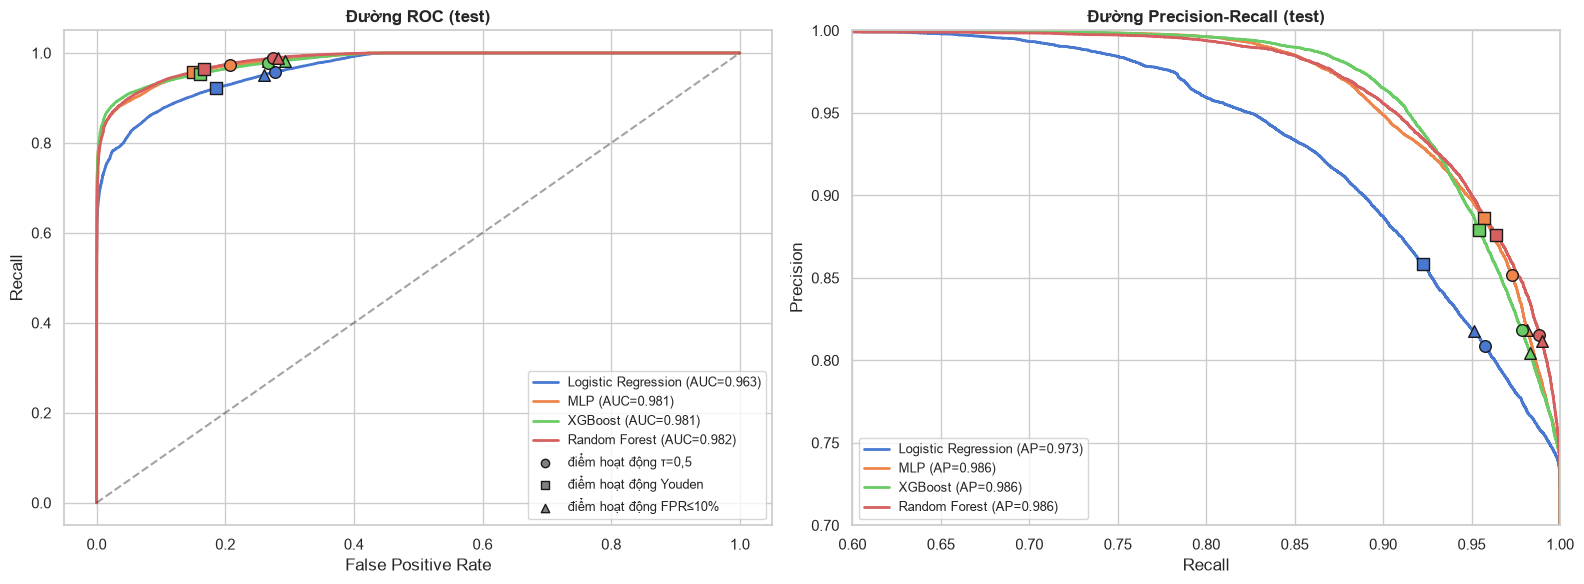

In [12]:
colors = dict(zip(MODELS, sns.color_palette('muted', 4)))
markers = {'τ=0,5': 'o', 'Youden': 's', 'FPR≤10%': '^'}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name in MODELS:
    pt, thr = probs0[name]
    fpr, tpr, _ = roc_curve(y_test, pt)
    prec, rec, _ = precision_recall_curve(y_test, pt)
    axes[0].plot(fpr, tpr, color=colors[name], linewidth=2, label=f'{name} (AUC={roc_auc_score(y_test, pt):.3f})')
    axes[1].plot(rec, prec, color=colors[name], linewidth=2, label=f'{name} (AP={average_precision_score(y_test, pt):.3f})')
    for op, mk in markers.items():
        pred = (pt >= thr[op]).astype(int)
        axes[0].scatter([fpr_of(y_test, pred)], [recall_score(y_test, pred)], color=colors[name], marker=mk, s=70, edgecolor='k', zorder=5)
        axes[1].scatter([recall_score(y_test, pred)], [precision_score(y_test, pred)], color=colors[name], marker=mk, s=70, edgecolor='k', zorder=5)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('Recall'); axes[0].set_title('Đường ROC (test)', fontweight='bold')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Đường Precision-Recall (test)', fontweight='bold')
axes[1].set_xlim(0.6, 1.0); axes[1].set_ylim(0.7, 1.0)
for op, mk in markers.items():
    axes[0].scatter([], [], marker=mk, color='gray', edgecolor='k', label=f'điểm hoạt động {op}')
axes[0].legend(fontsize=9, loc='lower right'); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## Phần 11: Toàn bộ test so với phần test chưa thấy

Khoảng 10% dòng test có bản sao y hệt trong train. Bảng dưới cho biết điểm số thay đổi thế nào khi chỉ chấm trên các dòng mô hình **chưa từng thấy** (cấu hình tinh chỉnh, trung bình ± std qua seed).

In [13]:
tuned_all = res_all[res_all['Cấu hình'] == 'Tinh chỉnh']
for op in ['τ=0,5', 'Youden']:
    sub = tuned_all[tuned_all['Điểm hoạt động'] == op]
    out = {}
    for col in ['F1', 'Recall', 'FPR', 'ROC-AUC (test)']:
        g = sub.groupby(['Mô hình', 'Tập test'])[col].agg(['mean', 'std'])
        t = g.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1).unstack('Tập test')
        for s in ['Toàn bộ', 'Chưa thấy']:
            out[(col, s)] = t[s]
    print(f'\n=== Điểm hoạt động: {op} ===')
    display(pd.DataFrame(out).loc[MODELS])


=== Điểm hoạt động: τ=0,5 ===


F1                            Recall  \
                             Toàn bộ        Chưa thấy          Toàn bộ   
Mô hình                                                                  
Logistic Regression  0.8656 ± 0.0066  0.8490 ± 0.0074  0.9805 ± 0.0131   
MLP                  0.8949 ± 0.0079  0.8826 ± 0.0091  0.9775 ± 0.0043   
XGBoost              0.8914 ± 0.0000  0.8789 ± 0.0000  0.9784 ± 0.0000   
Random Forest        0.8933 ± 0.0003  0.8813 ± 0.0003  0.9882 ± 0.0003   

                                                  FPR                   \
                           Chưa thấy          Toàn bộ        Chưa thấy   
Mô hình                                                                  
Logistic Regression  0.9772 ± 0.0155  0.3497 ± 0.0413  0.3502 ± 0.0433   
MLP                  0.9737 ± 0.0051  0.2539 ± 0.0264  0.2509 ± 0.0274   
XGBoost              0.9748 ± 0.0000  0.2658 ± 0.0000  0.2620 ± 0.0000   
Random Forest        0.9864 ± 0.0004  0.2747 ± 0.0007  0.2716 ± 0.0006   

                      ROC-AUC (test)                   
                             Toàn bộ        Chưa thấy  
Mô hình                                                
Logistic Regression  0.9630 ± 0.0008  0.9578 ± 0.0009  
MLP                  0.9801 ± 0.0014  0.9768 ± 0.0016  
XGBoost              0.9812 ± 0.0000  0.9781 ± 0.0000  
Random Forest        0.9821 ± 0.0002  0.9794 ± 0.0002


=== Điểm hoạt động: Youden ===


F1                            Recall  \
                             Toàn bộ        Chưa thấy          Toàn bộ   
Mô hình                                                                  
Logistic Regression  0.8872 ± 0.0021  0.8714 ± 0.0024  0.9274 ± 0.0084   
MLP                  0.9177 ± 0.0046  0.9075 ± 0.0050  0.9557 ± 0.0034   
XGBoost              0.9152 ± 0.0000  0.9040 ± 0.0000  0.9541 ± 0.0000   
Random Forest        0.9182 ± 0.0025  0.9085 ± 0.0027  0.9623 ± 0.0038   

                                                  FPR                   \
                           Chưa thấy          Toàn bộ        Chưa thấy   
Mô hình                                                                  
Logistic Regression  0.9146 ± 0.0098  0.2001 ± 0.0179  0.1989 ± 0.0177   
MLP                  0.9479 ± 0.0040  0.1559 ± 0.0135  0.1520 ± 0.0130   
XGBoost              0.9461 ± 0.0000  0.1605 ± 0.0000  0.1584 ± 0.0000   
Random Forest        0.9558 ± 0.0045  0.1639 ± 0.0124  0.1599 ± 0.0123   

                      ROC-AUC (test)                   
                             Toàn bộ        Chưa thấy  
Mô hình                                                
Logistic Regression  0.9630 ± 0.0008  0.9578 ± 0.0009  
MLP                  0.9801 ± 0.0014  0.9768 ± 0.0016  
XGBoost              0.9812 ± 0.0000  0.9781 ± 0.0000  
Random Forest        0.9821 ± 0.0002  0.9794 ± 0.0002

## Phần 12: Khoảng tin cậy 95% (bootstrap theo nhóm trùng lặp)

Độ lệch chuẩn qua 5 seed chỉ đo **độ ngẫu nhiên của mô hình**. Bootstrap đo thêm **độ bất định do tập test hữu hạn**: lấy mẫu lại tập test `N_BOOT` lần và tính lại các chỉ số.

- Lấy mẫu theo **nhóm dòng trùng lặp** (cluster bootstrap): các dòng giống hệt nhau được lấy cùng nhau, vì chúng không phải các quan sát độc lập.
- Dùng mô hình **đã tinh chỉnh ở seed đầu tiên**; ngưỡng giữ nguyên như đã chọn trên validation.
- Khoảng tin cậy là phân vị 2,5% và 97,5%.

In [14]:
grp_codes, grp_inv = np.unique(h_test, return_inverse=True)
n_groups = len(grp_codes)
rng = np.random.RandomState(BOOT_SEED)
boot_w = [np.bincount(rng.randint(0, n_groups, n_groups), minlength=n_groups)[grp_inv] for _ in range(N_BOOT)]

def wmetrics(y, prob, thr, w):
    out = {'ROC-AUC': roc_auc_score(y, prob, sample_weight=w),
           'AP': average_precision_score(y, prob, sample_weight=w)}
    for op in OPS:
        pred = (prob >= thr[op]).astype(int)
        tp = np.sum(w * ((pred == 1) & (y == 1))); fp = np.sum(w * ((pred == 1) & (y == 0)))
        fn = np.sum(w * ((pred == 0) & (y == 1))); tn = np.sum(w * ((pred == 0) & (y == 0)))
        rec = tp / (tp + fn); prec = tp / (tp + fp) if tp + fp else 0.0
        out[f'Recall | {op}'] = rec
        out[f'Precision | {op}'] = prec
        out[f'FPR | {op}'] = fp / (fp + tn)
        out[f'F1 | {op}'] = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return out

t0 = time.time()
point, boot = {}, {}
for name in MODELS:
    pt, thr = probs0[name]
    point[name] = wmetrics(y_test, pt, thr, np.ones(len(y_test)))
    samples = []
    for w in boot_w:
        nz = w > 0
        samples.append(wmetrics(y_test[nz], pt[nz], thr, w[nz]))
    boot[name] = pd.DataFrame(samples)
print(f'Bootstrap xong: {N_BOOT} lần × {len(MODELS)} mô hình, {n_groups:,} nhóm ({time.time()-t0:.0f}s)')

Bootstrap xong: 1000 lần × 4 mô hình, 53,946 nhóm (41s)


In [15]:
show = ['ROC-AUC', 'AP'] + [f'{m} | {op}' for op in OPS for m in ['Recall', 'Precision', 'FPR', 'F1']]
ci = pd.DataFrame({name: {k: f"{point[name][k]:.4f} [{boot[name][k].quantile(0.025):.4f}, {boot[name][k].quantile(0.975):.4f}]"
                          for k in show} for name in MODELS})
ci.index.name = 'Chỉ số (giá trị [CI 95%])'
display(ci)

ci_rows = []
for name in MODELS:
    for k in show:
        ci_rows.append({'Mô hình': name, 'Chỉ số': k, 'Giá trị': point[name][k],
                        'CI 2.5%': boot[name][k].quantile(0.025), 'CI 97.5%': boot[name][k].quantile(0.975)})
pd.DataFrame(ci_rows).to_csv(os.path.join(OUT_DIR, 'bootstrap_ci.csv'), index=False)

,Logistic Regression,MLP,XGBoost,Random Forest
Chỉ số (giá trị [CI 95%]),,,,
ROC-AUC,"0.9634 [0.9617, 0.9647]","0.9809 [0.9799, 0.9818]","0.9812 [0.9802, 0.9821]","0.9822 [0.9813, 0.9830]"
AP,"0.9726 [0.9708, 0.9741]","0.9858 [0.9848, 0.9867]","0.9863 [0.9853, 0.9872]","0.9865 [0.9854, 0.9873]"
"Recall | τ=0,5","0.9577 [0.9554, 0.9600]","0.9731 [0.9711, 0.9748]","0.9784 [0.9767, 0.9800]","0.9884 [0.9870, 0.9896]"
"Precision | τ=0,5","0.8087 [0.8029, 0.8142]","0.8517 [0.8467, 0.8567]","0.8185 [0.8127, 0.8241]","0.8154 [0.8099, 0.8208]"
"FPR | τ=0,5","0.2775 [0.2724, 0.2829]","0.2075 [0.2026, 0.2122]","0.2658 [0.2608, 0.2711]","0.2741 [0.2690, 0.2791]"
"F1 | τ=0,5","0.8769 [0.8730, 0.8805]","0.9084 [0.9052, 0.9115]","0.8914 [0.8877, 0.8948]","0.8936 [0.8901, 0.8970]"
Recall | Youden,"0.9223 [0.9187, 0.9255]","0.9573 [0.9546, 0.9596]","0.9541 [0.9515, 0.9565]","0.9639 [0.9614, 0.9662]"
Precision | Youden,"0.8585 [0.8536, 0.8633]","0.8866 [0.8821, 0.8909]","0.8792 [0.8745, 0.8838]","0.8760 [0.8713, 0.8806]"
FPR | Youden,"0.1862 [0.1817, 0.1909]","0.1501 [0.1456, 0.1544]","0.1605 [0.1565, 0.1651]","0.1672 [0.1626, 0.1718]"


### So sánh ghép cặp giữa các mô hình

Với mỗi cặp (A, B), tính `A − B` trên **cùng một mẫu bootstrap**. Khác biệt được coi là **có ý nghĩa** khi khoảng tin cậy 95% không chứa 0.

In [16]:
from itertools import combinations
cmp_metrics = ['ROC-AUC', 'F1 | τ=0,5', 'F1 | Youden', 'Recall | FPR≤10%', 'FPR | Youden']
pair_rows = []
for a, b in combinations(MODELS, 2):
    for k in cmp_metrics:
        d = boot[a][k].values - boot[b][k].values
        lo, hi = np.quantile(d, [0.025, 0.975])
        pair_rows.append({'A': a, 'B': b, 'Chỉ số': k, 'A − B': point[a][k] - point[b][k],
                          'CI 2.5%': lo, 'CI 97.5%': hi, 'P(A > B)': (d > 0).mean(),
                          'Có ý nghĩa': 'có' if (lo > 0 or hi < 0) else 'không'})
pairs = pd.DataFrame(pair_rows)
pairs.to_csv(os.path.join(OUT_DIR, 'bootstrap_pairwise.csv'), index=False)
for k in cmp_metrics:
    print(f'\n=== {k} ===')
    display(pairs[pairs['Chỉ số'] == k].drop(columns='Chỉ số').set_index(['A', 'B']).round(4))


=== ROC-AUC ===


A − B  CI 2.5%  CI 97.5%  P(A > B)  \
A                   B                                                    
Logistic Regression MLP           -0.0176  -0.0185   -0.0167     0.000   
                    XGBoost       -0.0179  -0.0189   -0.0169     0.000   
                    Random Forest -0.0188  -0.0198   -0.0179     0.000   
MLP                 XGBoost       -0.0003  -0.0008    0.0002     0.126   
                    Random Forest -0.0013  -0.0017   -0.0008     0.000   
XGBoost             Random Forest -0.0010  -0.0014   -0.0005     0.000   

                                  Có ý nghĩa  
A                   B                         
Logistic Regression MLP                   có  
                    XGBoost               có  
                    Random Forest         có  
MLP                 XGBoost            không  
                    Random Forest         có  
XGBoost             Random Forest         có


=== F1 | τ=0,5 ===


A − B  CI 2.5%  CI 97.5%  P(A > B)  \
A                   B                                                    
Logistic Regression MLP           -0.0315  -0.0333   -0.0296       0.0   
                    XGBoost       -0.0145  -0.0161   -0.0127       0.0   
                    Random Forest -0.0167  -0.0184   -0.0149       0.0   
MLP                 XGBoost        0.0170   0.0155    0.0185       1.0   
                    Random Forest  0.0148   0.0133    0.0162       1.0   
XGBoost             Random Forest -0.0022  -0.0034   -0.0011       0.0   

                                  Có ý nghĩa  
A                   B                         
Logistic Regression MLP                   có  
                    XGBoost               có  
                    Random Forest         có  
MLP                 XGBoost               có  
                    Random Forest         có  
XGBoost             Random Forest         có


=== F1 | Youden ===


A − B  CI 2.5%  CI 97.5%  P(A > B)  \
A                   B                                                    
Logistic Regression MLP           -0.0313  -0.0333   -0.0293       0.0   
                    XGBoost       -0.0259  -0.0282   -0.0237       0.0   
                    Random Forest -0.0286  -0.0307   -0.0264       0.0   
MLP                 XGBoost        0.0054   0.0037    0.0069       1.0   
                    Random Forest  0.0027   0.0014    0.0042       1.0   
XGBoost             Random Forest -0.0027  -0.0040   -0.0012       0.0   

                                  Có ý nghĩa  
A                   B                         
Logistic Regression MLP                   có  
                    XGBoost               có  
                    Random Forest         có  
MLP                 XGBoost               có  
                    Random Forest         có  
XGBoost             Random Forest         có


=== Recall | FPR≤10% ===


A − B  CI 2.5%  CI 97.5%  P(A > B)  \
A                   B                                                    
Logistic Regression MLP           -0.0299  -0.0323   -0.0276     0.000   
                    XGBoost       -0.0314  -0.0338   -0.0291     0.000   
                    Random Forest -0.0380  -0.0404   -0.0357     0.000   
MLP                 XGBoost       -0.0015  -0.0030   -0.0001     0.011   
                    Random Forest -0.0081  -0.0096   -0.0067     0.000   
XGBoost             Random Forest -0.0066  -0.0077   -0.0054     0.000   

                                  Có ý nghĩa  
A                   B                         
Logistic Regression MLP                   có  
                    XGBoost               có  
                    Random Forest         có  
MLP                 XGBoost               có  
                    Random Forest         có  
XGBoost             Random Forest         có


=== FPR | Youden ===


A − B  CI 2.5%  CI 97.5%  P(A > B)  \
A                   B                                                    
Logistic Regression MLP            0.0361   0.0328    0.0396       1.0   
                    XGBoost        0.0257   0.0218    0.0297       1.0   
                    Random Forest  0.0190   0.0150    0.0226       1.0   
MLP                 XGBoost       -0.0105  -0.0141   -0.0069       0.0   
                    Random Forest -0.0171  -0.0200   -0.0142       0.0   
XGBoost             Random Forest -0.0067  -0.0099   -0.0038       0.0   

                                  Có ý nghĩa  
A                   B                         
Logistic Regression MLP                   có  
                    XGBoost               có  
                    Random Forest         có  
MLP                 XGBoost               có  
                    Random Forest         có  
XGBoost             Random Forest         có

## Phần 13: Đầu ra

Thư mục `output_baseline/`:
- `summary.csv`: bảng kết quả chính (cấu hình tinh chỉnh, toàn bộ test, trung bình và độ lệch chuẩn qua 5 seed, theo mô hình và điểm hoạt động)
- `best_params.json`: siêu tham số tốt nhất, bàn giao cho nhóm federated
- `runs.csv`: kết quả từng lần chạy (mô hình × cấu hình × seed × điểm hoạt động × tập test)
- `per_category.csv`: recall theo loại tấn công
- `bootstrap_ci.csv`, `bootstrap_pairwise.csv`: khoảng tin cậy 95% và so sánh ghép cặp
- `models/*.joblib`: mô hình đã tinh chỉnh ở seed đầu tiên

Nhóm federated nên dùng cùng `output_preprocess/`, cùng siêu tham số trong `best_params.json` (hoặc tinh chỉnh riêng cho federated) và cùng điểm hoạt động để so sánh công bằng.